# Week 10 – CNN Laboratory Activity
**IT414 – IT Elective 3 (DSS Technologies)**


**Dataset:** CIFAR-10 (32×32 RGB, 10 classes)  
**Framework:** TensorFlow / Keras

> Run in Google Colab (Runtime → Change runtime type → GPU). Take a screenshot of the output of each task section.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1 – Problem framing & data plan
**Task statement:** Multi-class image classification on CIFAR-10. Input: 32×32×3 RGB images. Output: 1 of 10 classes.

In [ ]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

# Fixed, stratified train/val split (seed fixed) -> test set is never touched until final evaluation
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=5000, stratify=y_train_full, random_state=SEED
)

print(f"Total images : {len(x_train) + len(x_val) + len(x_test):,}")
print(f"Train        : {len(x_train):,}")
print(f"Validation   : {len(x_val):,}")
print(f"Test         : {len(x_test):,}")
print(f"Input shape  : {x_train.shape[1:]}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 912s 5us/step
Total images : 60,000
Train        : 45,000
Validation   : 5,000
Test         : 10,000
Input shape  : (32, 32, 3)


,class,train,val,test,total
0,airplane,4500,500,1000,6000
1,automobile,4500,500,1000,6000
2,bird,4500,500,1000,6000
3,cat,4500,500,1000,6000
4,deer,4500,500,1000,6000
5,dog,4500,500,1000,6000
6,frog,4500,500,1000,6000
7,horse,4500,500,1000,6000
8,ship,4500,500,1000,6000
9,truck,4500,500,1000,6000


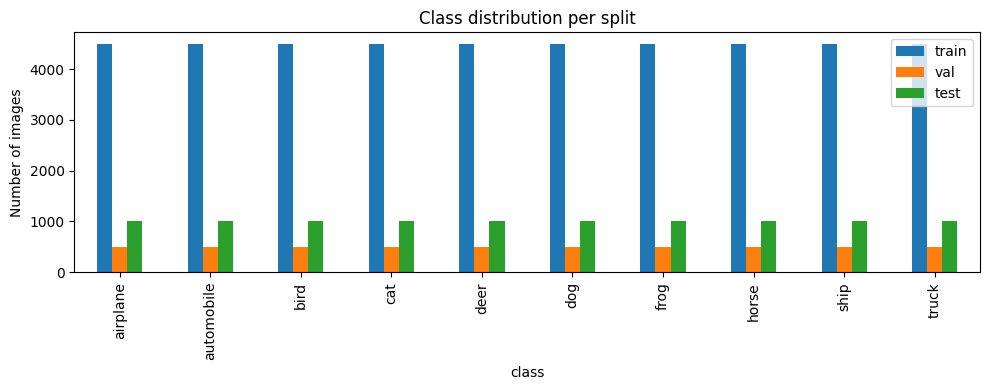

Imbalance note: max/min class count ratio (train) = 1.0 (1.0 = perfectly balanced)


In [ ]:
# Class names & counts per split (check for imbalance)
counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=10),
    "val":   np.bincount(y_val,   minlength=10),
    "test":  np.bincount(y_test,  minlength=10),
})
counts["total"] = counts[["train", "val", "test"]].sum(axis=1)
display(counts)

ax = counts.set_index("class")[["train", "val", "test"]].plot(kind="bar", figsize=(10, 4))
ax.set_title("Class distribution per split")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

print("Imbalance note: max/min class count ratio (train) =",
      round(counts['train'].max() / counts['train'].min(), 3), "(1.0 = perfectly balanced)")

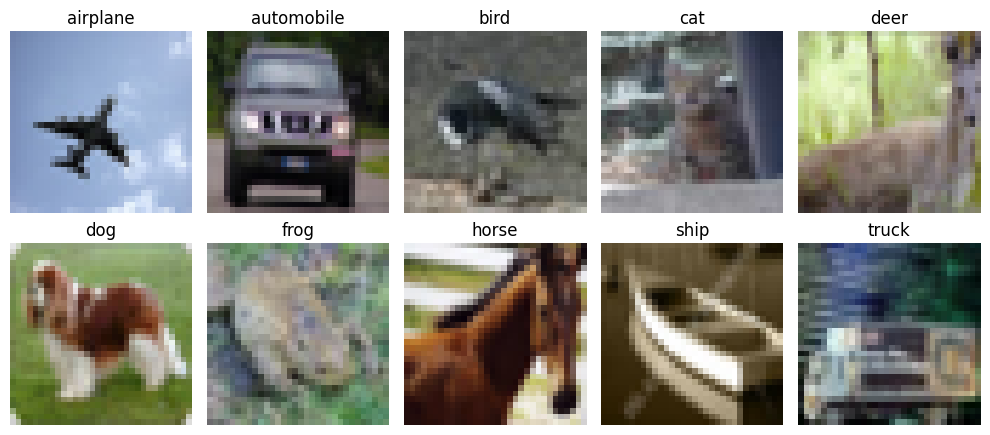

In [ ]:
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(CLASS_NAMES[i])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Preprocessing: keep native 32x32 (no resizing), scale pixels to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

INPUT_SHAPE = x_train.shape[1:]   # (32, 32, 3)
NUM_CLASSES = 10
BATCH_SIZE = 64
EPOCHS = 20                        # lab limit: <= 20

print("Input size  :", INPUT_SHAPE)
print("Pixel range :", x_train.min(), "-", x_train.max())

Input size  : (32, 32, 3)
Pixel range : 0.0 - 0.003921569


## Task 2 – Model 1: User-defined baseline CNN
**Design:** 3 × [Conv → ReLU → MaxPool] → Flatten → Dense(64) → Softmax(10). Small capacity, no regularization, so it is a clear reference point.

**Training plan:** Adam (lr = 1e-3), batch size 64, max 20 epochs, EarlyStopping on `val_loss` (patience = 3, restore best weights).

In [ ]:
def build_baseline():
    model = keras.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="baseline_cnn")
    return model

baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

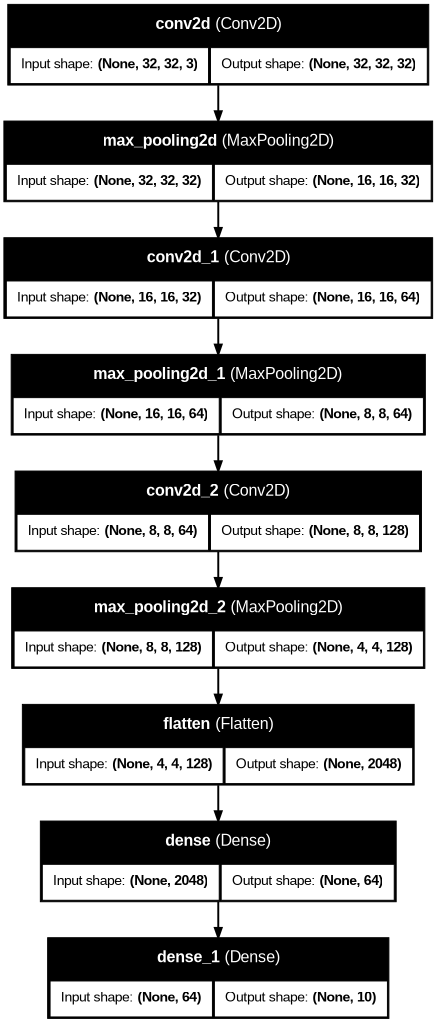

In [ ]:
# Layer diagram (needs graphviz; preinstalled on Colab). Safe to skip if it errors.
try:
    display(keras.utils.plot_model(baseline, show_shapes=True, show_layer_names=True, dpi=70))
except Exception as e:
    print("plot_model unavailable:", e)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

hist_base = baseline.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop], verbose=2
)

Epoch 1/20
704/704 - 9s - 13ms/step - accuracy: 0.1007 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/20
704/704 - 3s - 5ms/step - accuracy: 0.0995 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/20
704/704 - 3s - 5ms/step - accuracy: 0.0992 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/20
704/704 - 3s - 5ms/step - accuracy: 0.0992 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026


## Task 3 – Model 2: Stronger CNN (deeper + BatchNorm + Dropout)
**Design:** 3 stages of [Conv → BN → ReLU → Conv → BN → ReLU → MaxPool → Dropout(0.25)] with 32 / 64 / 128 filters, then Dense(128) → BN → Dropout(0.5) → Softmax(10).  
**Augmentation (training only):** random horizontal flip + small random translation (declared in the appendix).  
**Training plan:** same optimizer, batch size, epochs and early stopping as Model 1 for a fair comparison.

In [ ]:
def conv_bn_relu(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def build_stronger():
    inputs = keras.Input(shape=INPUT_SHAPE)
    # Augmentation layers are only active during training
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.1, 0.1)(x)

    for filters in (32, 64, 128):
        x = conv_bn_relu(x, filters)
        x = conv_bn_relu(x, filters)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="stronger_cnn")

stronger = build_stronger()
stronger.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])
stronger.summary()

Model: "stronger_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

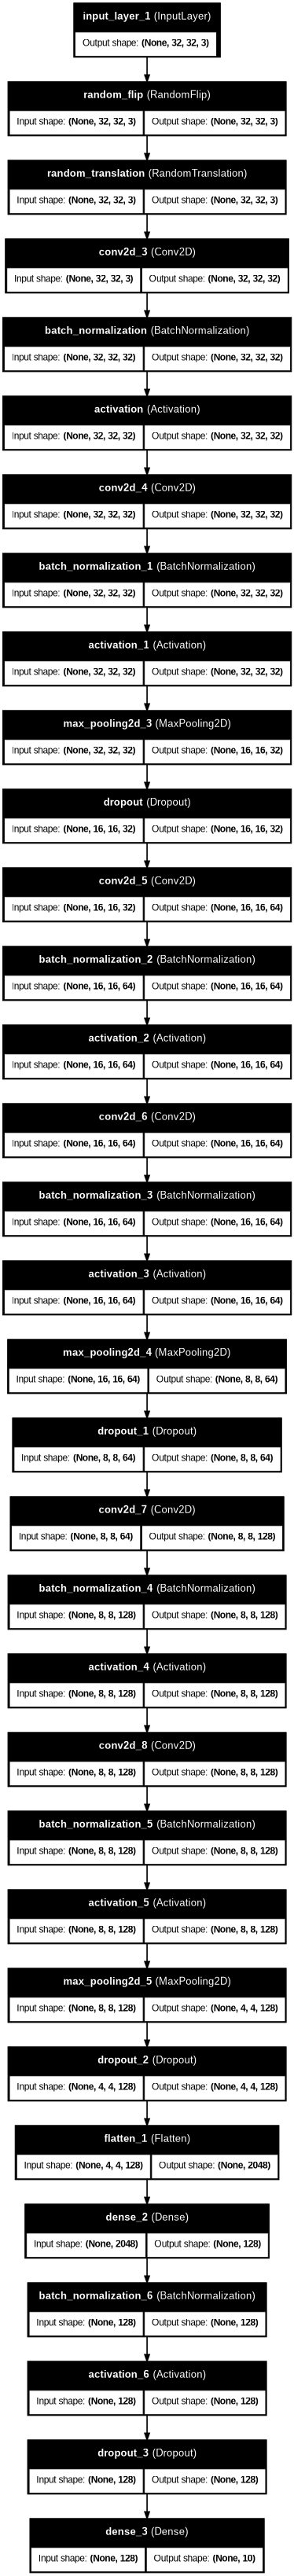

In [ ]:
try:
    display(keras.utils.plot_model(stronger, show_shapes=True, show_layer_names=True, dpi=60))
except Exception as e:
    print("plot_model unavailable:", e)

In [ ]:
early_stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

hist_strong = stronger.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stop2], verbose=2
)

Epoch 1/20
704/704 - 21s - 30ms/step - accuracy: 0.4160 - loss: 1.6356 - val_accuracy: 0.4084 - val_loss: 1.7230
Epoch 2/20
704/704 - 13s - 18ms/step - accuracy: 0.5782 - loss: 1.1864 - val_accuracy: 0.6472 - val_loss: 0.9898
Epoch 3/20
704/704 - 13s - 18ms/step - accuracy: 0.6418 - loss: 1.0162 - val_accuracy: 0.6722 - val_loss: 0.9471
Epoch 4/20
704/704 - 13s - 18ms/step - accuracy: 0.6776 - loss: 0.9279 - val_accuracy: 0.6972 - val_loss: 0.8470
Epoch 5/20
704/704 - 13s - 18ms/step - accuracy: 0.7024 - loss: 0.8614 - val_accuracy: 0.6872 - val_loss: 0.9472
Epoch 6/20
704/704 - 13s - 18ms/step - accuracy: 0.7183 - loss: 0.8191 - val_accuracy: 0.6820 - val_loss: 0.9262
Epoch 7/20
704/704 - 13s - 18ms/step - accuracy: 0.7338 - loss: 0.7746 - val_accuracy: 0.7252 - val_loss: 0.8113
Epoch 8/20
704/704 - 13s - 18ms/step - accuracy: 0.7471 - loss: 0.7354 - val_accuracy: 0.7160 - val_loss: 0.8195
Epoch 9/20
704/704 - 13s - 18ms/step - accuracy: 0.7592 - loss: 0.7073 - val_accuracy: 0.7426 - 

## Task 4 – Validation & test evaluation (both models)

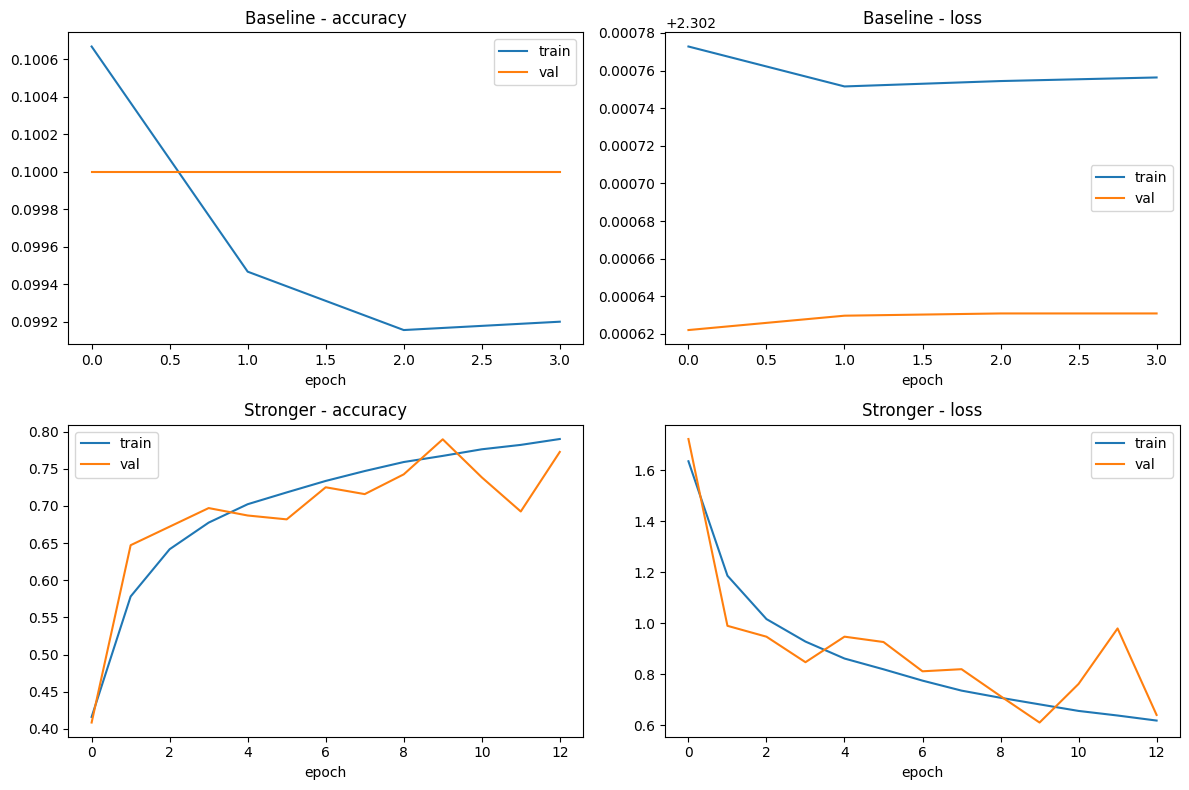

In [ ]:
# Training curves
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, h) in enumerate([("Baseline", hist_base), ("Stronger", hist_strong)]):
    axes[row, 0].plot(h.history["accuracy"], label="train")
    axes[row, 0].plot(h.history["val_accuracy"], label="val")
    axes[row, 0].set_title(f"{name} - accuracy"); axes[row, 0].set_xlabel("epoch"); axes[row, 0].legend()
    axes[row, 1].plot(h.history["loss"], label="train")
    axes[row, 1].plot(h.history["val_loss"], label="val")
    axes[row, 1].set_title(f"{name} - loss"); axes[row, 1].set_xlabel("epoch"); axes[row, 1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Best validation accuracy (+ epoch) and FINAL test accuracy (evaluated once per model)
def summarize(name, model, hist):
    val_acc = np.array(hist.history["val_accuracy"])
    best_epoch = int(val_acc.argmax()) + 1          # epochs are 1-indexed
    best_val = float(val_acc.max())
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    gap = hist.history["accuracy"][best_epoch - 1] - best_val
    return {"Model": name,
            "Best Val Acc": round(best_val, 4),
            "Epoch": best_epoch,
            "Test Acc": round(float(test_acc), 4),
            "Train-Val gap @best": round(float(gap), 4)}

results = pd.DataFrame([
    summarize("User-Defined Baseline", baseline, hist_base),
    summarize("Stronger CNN", stronger, hist_strong),
])
display(results)

,Model,Best Val Acc,Epoch,Test Acc,Train-Val gap @best
0,User-Defined Baseline,0.1000,1,0.1000,0.0007
1,Stronger CNN,0.7898,10,0.7747,-0.0223


Best model: Stronger CNN


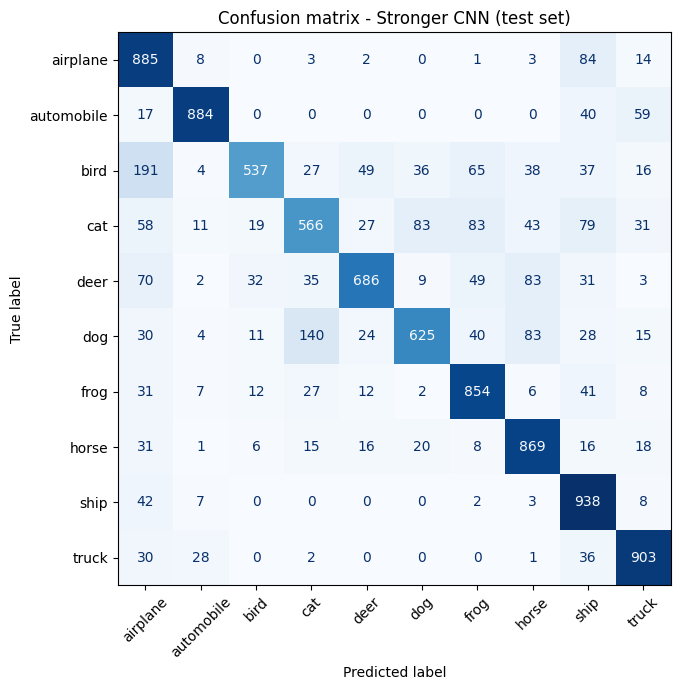

              precision    recall  f1-score   support

    airplane      0.639     0.885     0.742      1000
  automobile      0.925     0.884     0.904      1000
        bird      0.870     0.537     0.664      1000
         cat      0.694     0.566     0.624      1000
        deer      0.841     0.686     0.756      1000
         dog      0.806     0.625     0.704      1000
        frog      0.775     0.854     0.813      1000
       horse      0.770     0.869     0.816      1000
        ship      0.705     0.938     0.805      1000
       truck      0.840     0.903     0.870      1000

    accuracy                          0.775     10000
   macro avg      0.787     0.775     0.770     10000
weighted avg      0.787     0.775     0.770     10000



In [ ]:
# Confusion matrix for the best model (highest test accuracy)
best_name = results.loc[results["Test Acc"].idxmax(), "Model"]
best_model = baseline if best_name == "User-Defined Baseline" else stronger
print("Best model:", best_name)

y_pred = best_model.predict(x_test, verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix - {best_name} (test set)")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

In [ ]:
# Top confusions (helps you write the 2-3 line interpretation)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])) for i in range(10) for j in range(10) if off[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Most common confusions (true -> predicted : count)")
for t, p, c in pairs[:6]:
    print(f"  {t:>10} -> {p:<10}: {c}")

Most common confusions (true -> predicted : count)
        bird -> airplane  : 191
         dog -> cat       : 140
    airplane -> ship      : 84
         cat -> dog       : 83
         cat -> frog      : 83
        deer -> horse     : 83


### Results table (copy the values from the output above)

| Model | Best Val Acc | Epoch | Test Acc | Notes (1–2 bullets) |
|---|---|---|---|---|
| User-Defined Baseline | | | | |
| Stronger CNN | | | | |

### Confusion matrix interpretation (2–3 lines)
_Write this from your own matrix. Look at the "Most common confusions" output: which classes are mixed up, and why might they look similar (e.g., shape, background, 32×32 resolution)?_

### Reflection
_Compare the two models: did BatchNorm, Dropout and augmentation reduce the train–validation gap? Did the improvement justify the extra parameters and training time?_

## Appendix
- **Dataset:** CIFAR-10, Krizhevsky, A. (2009), *Learning Multiple Layers of Features from Tiny Images*. Source: https://www.cs.toronto.edu/~kriz/cifar.html (the dataset page does not state a formal license; it is freely available for research and educational use, so cite the source).
- **Splits (fixed, stratified, seed = 42):** train 45,000 / validation 5,000 / test 10,000 (official CIFAR-10 test set).
- **Input size:** 32×32×3, no resizing; pixels scaled to [0, 1].
- **Augmentations:** none for the baseline; Stronger CNN uses random horizontal flip and ±10% random translation (training only).
- **Training:** Adam (lr 1e-3), batch size 64, max 20 epochs, EarlyStopping on `val_loss` (patience 3, restore best weights).